# Этап 4. Валидация, модель и эксперименты
**Датасет:** `Student_Performance_cleaned.csv`

**Задачи:**
0. Определяем тип задачи и метрики, фиксируем `seed`, делим данные на train / validation / test.
1. Baseline (наивные модели для сравнения).
2. Обучаем 4 семейства алгоритмов, для каждого перебираем 6–8 значений ключевого гиперпараметра.
3. Оцениваем на валидационной части обучающих данных.
4. Графики «метрика – гиперпараметр» + выводы.
5–6. Повторяем всё с 5-кратной кросс-валидацией: среднее и стандартное отклонение, графики.
7. Итоговая таблица.
8. Лучшая модель: обучение на всех train-данных, единственная оценка на тесте.
9. Анализ ошибок (график остатков).

In [30]:
# 0. Импорты и воспроизводимость
import os, random, warnings
from pathlib import Path

SEED = 42                                    # единый seed для всего эксперимента
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)

import numpy as np
np.random.seed(SEED)
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

try:
    display
except NameError:                            # запуск как обычного .py-скрипта
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
FIG, RES = ROOT / "results" / "figures", ROOT / "results"
FIG.mkdir(parents=True, exist_ok=True)
print(f"scikit-learn {sklearn.__version__}, numpy {np.__version__}, pandas {pd.__version__}; SEED = {SEED}")

scikit-learn 1.6.1, numpy 2.4.6, pandas 2.2.3; SEED = 42


In [31]:
df = pd.read_csv("/content/Student_Performance_cleaned.csv")
TARGET = "Performance Index"
print("Размер:", df.shape, "| пропусков:", int(df.isna().sum().sum()), "| полных дубликатов:", int(df.duplicated().sum()))
display(df.describe().T.round(2))
X, y = df.drop(columns=TARGET), df[TARGET]

Размер: (9873, 6) | пропусков: 0 | полных дубликатов: 0


,count,mean,std,min,25%,50%,75%,max
Hours Studied,9873.0,4.99,2.59,1.0,3.0,5.0,7.0,9.0
Previous Scores,9873.0,69.44,17.33,40.0,54.0,69.0,85.0,99.0
Extracurricular Activities,9873.0,0.49,0.50,0.0,0.0,0.0,1.0,1.0
Sleep Hours,9873.0,6.53,1.70,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,9873.0,4.58,2.87,0.0,2.0,5.0,7.0,9.0
Performance Index,9873.0,55.22,19.21,10.0,40.0,55.0,70.0,100.0


## 0. Тип задачи и метрики

**Тип задачи — регрессия.** Целевая переменная `Performance Index` — числовой индекс успеваемости от 10 до 100
(91 различное значение, упорядоченная количественная шкала, расстояние между значениями имеет смысл).
Превращать её в классы значило бы терять информацию, поэтому предсказываем число.

**Метрики**:

| Метрика | Зачем | Как читать |
|---|---|---|
| **RMSE** (главная) | В тех же единицах, что и целевая переменная (баллы индекса). Квадрат штрафует крупные промахи сильнее мелких: сильно ошибиться в оценке студента хуже, чем несколько раз ошибиться чуть-чуть. | Типичная величина ошибки в баллах. Меньше – лучше. |
| **MAE** | Средний модуль ошибки. Прозрачна для интерпретации и меньше зависит от редких выбросов. Если MAE ≈ RMSE, то грубых промахов почти нет. | «В среднем ошибаемся на N баллов». |
| **R²** | Доля дисперсии цели, объяснённая моделью. Безразмерна, а значит удобна для сравнения с baseline: модель «всегда предсказывать среднее» даёт R² ≈ 0. | 0 – не лучше среднего, 1 – идеал. |

Не используем accuracy/F1 (это метрики классификации) и MAPE (не нужна: цель не бывает около нуля, а относительная ошибка здесь не важна).
**Модели сравниваем по RMSE**, MAE и R² – для контроля и интерпретации.

In [32]:
# Разбиение данных
# 80% – train_full (на нём живут и валидация, и кросс-валидация), 20% – test (хранится «в сейфе» до пункта 8).
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
# Из train_full выделяем валидацию (25% от него = 20% от всех данных).
X_fit, X_val, y_fit, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=SEED)

split = pd.DataFrame({"строк": [len(X_fit), len(X_val), len(X_test)],
                      "доля": [len(X_fit) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
                      "среднее цели": [y_fit.mean(), y_val.mean(), y_test.mean()],
                      "std цели": [y_fit.std(), y_val.std(), y_test.std()]},
                     index=["fit (обучение)", "val (валидация)", "test (тест, не трогаем)"]).round(3)
display(split)

,строк,доля,среднее цели,std цели
fit (обучение),5923,0.6,54.977,19.200
val (валидация),1975,0.2,55.454,19.145
"test (тест, не трогаем)",1975,0.2,55.699,19.296


**Схема данных.** Данные делятся один раз с фиксированным `random_state=42`:

```
все данные ─┬─ train_full (80%) ─┬─ fit (60%)   – обучение при подборе гиперпараметров (пункты 2–4)
            │                    └─ val (20%)   – валидация (пункты 3–4)
            │                    (вся train_full → 5-кратная кросс-валидация, пункты 5–6, и итоговое обучение, пункт 8)
            └─ test (20%)        – одна оценка лучшей модели в пункте 8
```
Среднее и разброс цели в трёх частях почти совпадают, значит разбиение репрезентативно.

In [33]:
# Вспомогательные функции
def metrics(y_true, y_pred):
    return {"rmse": root_mean_squared_error(y_true, y_pred),
            "mae": mean_absolute_error(y_true, y_pred),
            "r2": r2_score(y_true, y_pred)}

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def cv_scores(model, Xa, ya):
    """5-кратная кросс-валидация: среднее и std метрик на валидационных фолдах (+ среднее на обучающих)."""
    r = cross_validate(model, Xa, ya, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=1)
    out = {}
    for m in ("rmse", "mae", "r2"):
        sign = -1 if m != "r2" else 1
        out[f"cv_{m}_mean"] = sign * r[f"test_{m}"].mean()
        out[f"cv_{m}_std"] = r[f"test_{m}"].std()
        out[f"cv_train_{m}_mean"] = sign * r[f"train_{m}"].mean()
    return out

## 1. Baseline
Baseline нужен, чтобы понимать, **что значит хороший результат**. Берём три ориентира разной силы:

1. `Mean` – всегда предсказывать среднее обучающей выборки (**основной baseline**, нижняя граница; R² ≈ 0).
2. `Median` – то же с медианой.
3. `LinReg по Previous Scores` – «простое правило»: смотрим только на предыдущие баллы. Это уже содержательный ориентир: любая серьёзная модель обязана его обыграть.

Все baseline обучаются на тех же `fit`-данных и проверяются на `val`.

In [34]:
baselines = {
    "Baseline: Mean": DummyRegressor(strategy="mean"),
    "Baseline: Median": DummyRegressor(strategy="median"),
    "Baseline: LinReg по Previous Scores": Pipeline([
        ("sel", ColumnTransformer([("p", "passthrough", ["Previous Scores"])])),
        ("lr", LinearRegression())]),
}
rows = []
for name, mdl in baselines.items():
    mdl.fit(X_fit, y_fit)
    rows.append({"Модель": name, **{f"val_{k}": v for k, v in metrics(y_val, mdl.predict(X_val)).items()},
                 **cv_scores(mdl, X_train_full, y_train_full)})
baseline_df = pd.DataFrame(rows)
display(baseline_df[["Модель", "val_rmse", "val_mae", "val_r2"]].round(3))

,Модель,val_rmse,val_mae,val_r2
0,Baseline: Mean,19.146,16.086,-0.001
1,Baseline: Median,19.146,16.086,-0.001
2,Baseline: LinReg по Previous Scores,7.718,6.617,0.837


## 2. Модели и сетки гиперпараметров
Четыре семейства алгоритмов, принципиально по-разному устроенных:

| Модель | Идея | Варьируемый гиперпараметр | Что он регулирует |
|---|---|---|---|
| **Ridge** (линейная с L2-штрафом) | Взвешенная сумма признаков | `alpha` | Сила штрафа за большие коэффициенты |
| **KNN** | Усреднение целей ближайших похожих студентов | `n_neighbors` | Сколько соседей усредняем (гладкость) |
| **Random Forest** | Усреднение множества решающих деревьев | `max_depth` | Глубина дерева (сложность) |
| **Gradient Boosting** | Деревья, последовательно исправляющие ошибки друг друга | `n_estimators` | Число шагов бустинга |

Для Ridge и KNN признаки стандартизуются внутри `Pipeline` (`StandardScaler`), иначе «баллы» и «часы сна» будут влиять на расстояния и штраф несравнимо.
Масштабирование внутри `Pipeline` ещё и защищает от **утечки данных**: на каждой валидации/фолде оно обучается только на обучающей части.
У всех моделей со случайностью зафиксирован `random_state=42`.

In [46]:
GRID = {
    "Ridge": dict(param="alpha", values=[0.01, 1, 10, 100, 1000, 10000], log=True,
                  build=lambda v: Pipeline([("scaler", StandardScaler()), ("m", Ridge(alpha=v, random_state=SEED))]),
                  fixed="StandardScaler"),
    "KNN": dict(param="n_neighbors", values=[1, 3, 5, 10, 20, 50, 100, 200], log=True,
                build=lambda v: Pipeline([("scaler", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=v))]),
                fixed="weights=uniform, StandardScaler"),
    "Random Forest": dict(param="max_depth", values=[2, 4, 6, 8, 12, None], log=False,
                          build=lambda v: RandomForestRegressor(n_estimators=100, max_depth=v, random_state=SEED, n_jobs=-1),
                          fixed="n_estimators=100"),
    "Gradient Boosting": dict(param="n_estimators", values=[10, 25, 50, 100, 200, 400], log=True,
                              build=lambda v: GradientBoostingRegressor(n_estimators=v, learning_rate=0.1, max_depth=3, random_state=SEED),
                              fixed="learning_rate=0.1, max_depth=3"),
}
n_cfg = sum(len(g["values"]) for g in GRID.values())
print(f"Моделей: {len(GRID)}, всего конфигураций: {n_cfg}")
for k, g in GRID.items():
    print(f"  {k:18s} {g['param']:13s} = {g['values']}   (фиксировано: {g['fixed']})")

Моделей: 4, всего конфигураций: 26
  Ridge              alpha         = [0.01, 1, 10, 100, 1000, 10000]   (фиксировано: StandardScaler)
  KNN                n_neighbors   = [1, 3, 5, 10, 20, 50, 100, 200]   (фиксировано: weights=uniform, StandardScaler)
  Random Forest      max_depth     = [2, 4, 6, 8, 12, None]   (фиксировано: n_estimators=100)
  Gradient Boosting  n_estimators  = [10, 25, 50, 100, 200, 400]   (фиксировано: learning_rate=0.1, max_depth=3)


## 3. Оценка на валидационной части (без кросс-валидации)
Для каждой конфигурации: обучаем на `fit`, считаем метрики на `fit` (train) и на `val`.
Сравнение train и val показывает **недо- и переобучение**: если на train ошибка сильно меньше, чем на val, модель запоминает данные.

In [36]:
val_rows = []
for mname, g in GRID.items():
    for v in g["values"]:
        mdl = g["build"](v).fit(X_fit, y_fit)
        tr, va = metrics(y_fit, mdl.predict(X_fit)), metrics(y_val, mdl.predict(X_val))
        val_rows.append({"model": mname, "param": g["param"], "value": str(v),
                         **{f"train_{k}": x for k, x in tr.items()}, **{f"val_{k}": x for k, x in va.items()}})
val_df = pd.DataFrame(val_rows)
for mname in GRID:
    print(f"\n{mname} (по {GRID[mname]['param']})")
    display(val_df[val_df.model == mname][["value", "train_rmse", "val_rmse", "val_mae", "val_r2"]].round(4).reset_index(drop=True))


Ridge (по alpha)


,value,train_rmse,val_rmse,val_mae,val_r2
0,0.01,2.0419,2.0190,1.5970,0.9889
1,1,2.0419,2.0189,1.5970,0.9889
2,10,2.0421,2.0178,1.5965,0.9889
3,100,2.0666,2.0298,1.6106,0.9888
4,1000,3.4427,3.3596,2.7294,0.9692
5,10000,12.1874,12.1203,10.1503,0.5990



KNN (по n_neighbors)


,value,train_rmse,val_rmse,val_mae,val_r2
0,1,0.5970,4.2290,3.4025,0.9512
1,3,2.3618,3.3298,2.6716,0.9697
2,5,2.5488,3.1078,2.4544,0.9736
3,10,2.7459,2.9603,2.3436,0.9761
4,20,2.8445,2.9431,2.3049,0.9764
5,50,3.3809,3.3371,2.5347,0.9696
6,100,4.1312,4.0286,3.0317,0.9557
7,200,5.1844,5.1003,3.8276,0.9290



Random Forest (по max_depth)


,value,train_rmse,val_rmse,val_mae,val_r2
0,2,8.5024,8.5428,7.1650,0.8008
1,4,4.0151,3.9542,3.2175,0.9573
2,6,2.4948,2.5800,2.0623,0.9818
3,8,1.9812,2.2600,1.7893,0.9861
4,12,1.1311,2.3166,1.8381,0.9854
5,None,0.9397,2.3525,1.8689,0.9849



Gradient Boosting (по n_estimators)


,value,train_rmse,val_rmse,val_mae,val_r2
0,10,8.0494,7.9321,6.4006,0.8283
1,25,3.2796,3.2390,2.5622,0.9714
2,50,2.2074,2.2249,1.7633,0.9865
3,100,2.0293,2.1010,1.6628,0.9880
4,200,1.9875,2.0997,1.6652,0.9880
5,400,1.9479,2.1116,1.6751,0.9878


## 4. Графики: метрики в зависимости от гиперпараметров (валидация)
Сплошная линия – валидация, пунктир – обучающая часть. Три строки: RMSE, MAE, R².

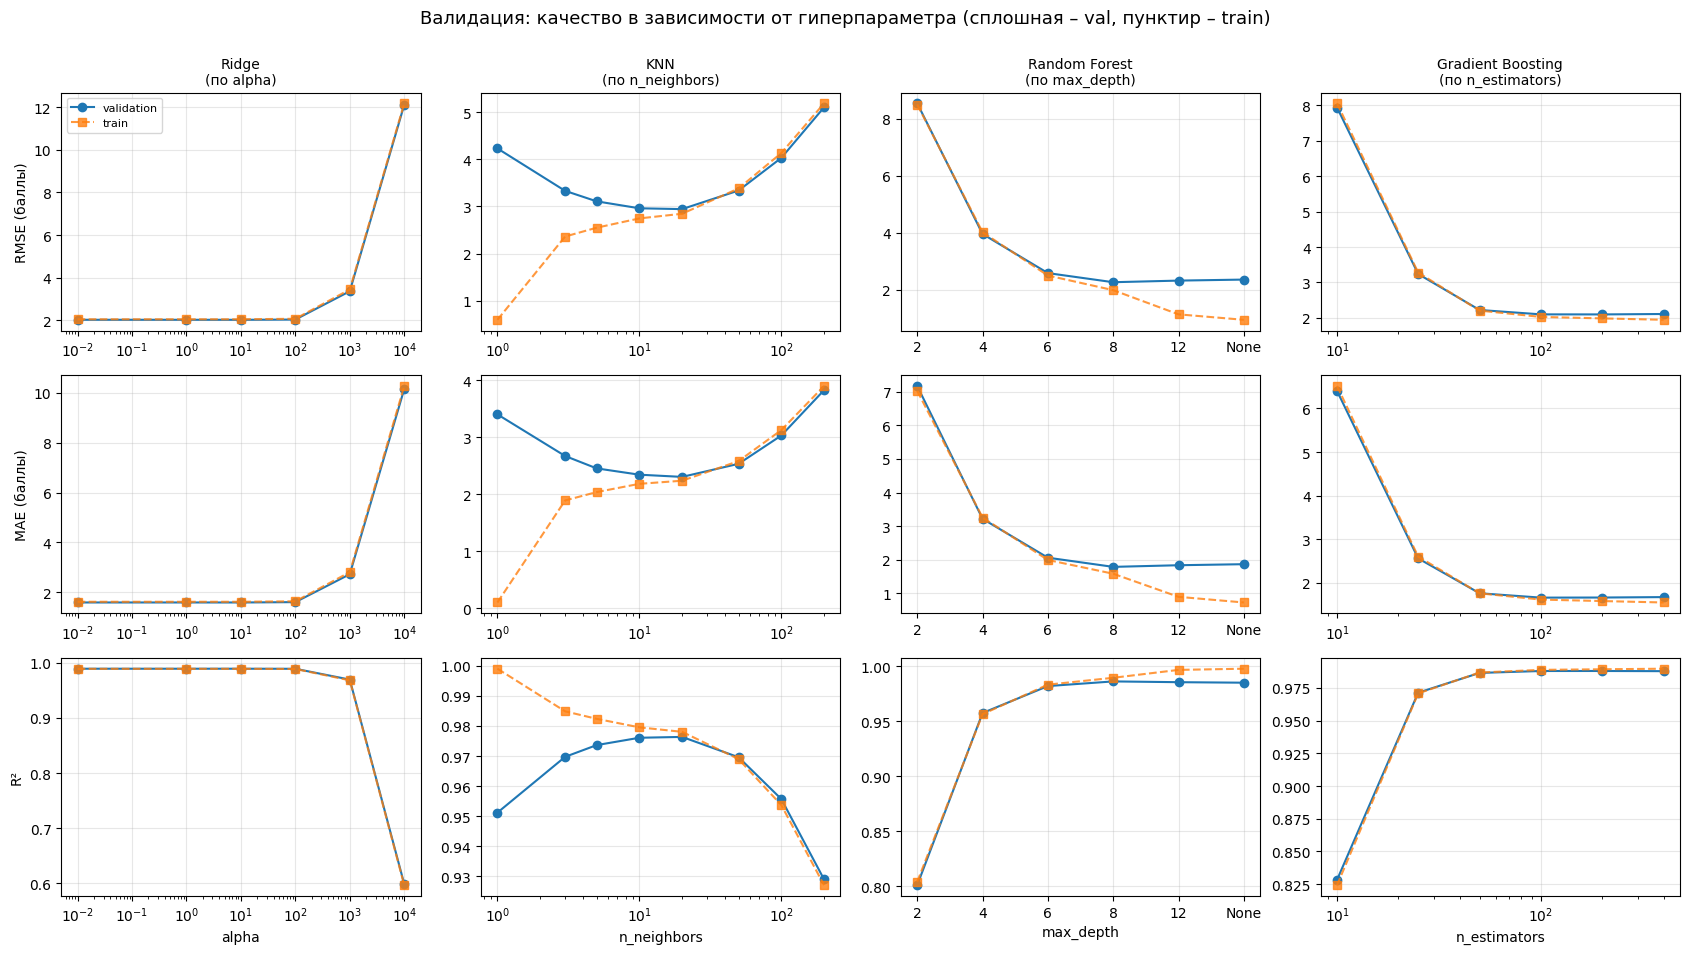

In [37]:
LABEL = {"rmse": "RMSE (баллы)", "mae": "MAE (баллы)", "r2": "R²"}

def xpos(g):
    vals = g["values"]
    if any(v is None for v in vals):
        return list(range(len(vals))), [str(v) for v in vals]
    return vals, None

def plot_sweeps(table, kind, fname, title):
    """kind = 'val' (одно разбиение) или 'cv' (кросс-валидация, с полосой ±std)."""
    fig, axes = plt.subplots(3, 4, figsize=(17, 9.5))
    for j, (mname, g) in enumerate(GRID.items()):
        sub = table[table.model == mname].reset_index(drop=True)
        x, ticks = xpos(g)
        for i, m in enumerate(("rmse", "mae", "r2")):
            ax = axes[i, j]
            if kind == "val":
                ax.plot(x, sub[f"val_{m}"], "o-", color="C0", label="validation")
                ax.plot(x, sub[f"train_{m}"], "s--", color="C1", alpha=.8, label="train")
            else:
                mu, sd = sub[f"cv_{m}_mean"].to_numpy(), sub[f"cv_{m}_std"].to_numpy()
                ax.plot(x, mu, "o-", color="C0", label="CV: среднее по 5 фолдам")
                ax.fill_between(x, mu - sd, mu + sd, color="C0", alpha=.25, label="±1 std")
                ax.plot(x, sub[f"cv_train_{m}_mean"], "s--", color="C1", alpha=.8, label="train (среднее)")
            if g["log"]: ax.set_xscale("log")
            if ticks: ax.set_xticks(x); ax.set_xticklabels(ticks)
            if i == 0: ax.set_title(f"{mname}\n(по {g['param']})", fontsize=10)
            if i == 2: ax.set_xlabel(g["param"])
            if j == 0: ax.set_ylabel(LABEL[m])
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title, fontsize=13, y=1.0)
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=130, bbox_inches="tight")
    plt.show()

plot_sweeps(val_df, "val", "01_validation_metrics_vs_hyperparams.png",
            "Валидация: качество в зависимости от гиперпараметра (сплошная – val, пунктир – train)")

### Выводы по пункту 4 (валидация)
**Ориентиры.** Baseline «всегда среднее» даёт RMSE ≈ 19.1 и R² ≈ 0: среднее ничего не знает о студенте. Уже один признак `Previous Scores` снижает RMSE до 7.7 (R² 0.84). Всё, что хуже 7.7, смысла не имеет.

**Ridge (`alpha`).** При `alpha` от 0.01 до 100 кривая плоская (RMSE ≈ 2.02–2.03), train и val совпадают. Штраф начинает вредить при `alpha ≥ 1000`: RMSE 3.4, а при 10 000 – 12.1 (R² падает с 0.99 до 0.60). Это **недообучение**: слишком сильный штраф прижимает коэффициенты к нулю, модель перестаёт пользоваться признаками, и ошибка велика и на train, и на val. Вывод: этим данным регуляризация не нужна, у линейной модели с 5 признаками и ~6 тыс. строк нет проблемы переобучения.

**KNN (`n_neighbors`).** U-образная кривая – классический компромисс смещения и разброса. При k=1 train RMSE 0.60, а val 4.23: **переобучение** (модель повторяет единственного соседа вместе с его шумом). При k ≥ 50 train и val сходятся, но обе растут: **недообучение** (усредняются слишком разные студенты). Оптимум k ≈ 10–20 (val RMSE 2.94–2.96).

**Random Forest (`max_depth`).** При глубине 2 RMSE 8.5 (недообучение: 4 листа не описывают плавную зависимость). Быстрое улучшение до глубины 8 (RMSE 2.26). Дальше train продолжает падать (1.98 → 1.13 → 0.94), а val слегка растёт (2.26 → 2.32 → 2.35): начинается переобучение, но мягкое, так как усреднение 100 деревьев его сглаживает.

**Gradient Boosting (`n_estimators`).** 10 деревьев – недообучение (RMSE 7.9), быстрый спад до 50–100 деревьев, затем плато (100: 2.101; 200: 2.100; 400: 2.112). Больше 200 шагов ничего не даёт; train и val почти совпадают, то есть при `learning_rate=0.1`, `max_depth=3` переобучения практически нет.

**Общее.** Три принципиально разные модели независимо упираются в потолок ≈ 2.0–2.1 RMSE, причём лучшая из деревьев (бустинг, 2.10) не обгоняет простую линейную (2.02). Можно предположить, что остаточная ошибка – шум, а не нехватка сложности модели.

## 5–6.  5-кратная кросс-валидация
**Зачем.** Одно разбиение на `val` даёт одну оценку, и она зависит от того, какие именно 20% строк попали в валидацию.
`KFold(n_splits=5, shuffle=True, random_state=42)` делит `train_full` на 5 частей; каждая часть по очереди становится валидацией,
остальные четыре – обучением. Получаем 5 оценок: **среднее** показывает качество, **std** – насколько оно устойчиво.
Тестовая выборка по-прежнему не используется.

In [38]:
cv_rows = []
for mname, g in GRID.items():
    for v in g["values"]:
        cv_rows.append({"model": mname, "param": g["param"], "value": str(v),
                        **cv_scores(g["build"](v), X_train_full, y_train_full)})
cv_df = pd.DataFrame(cv_rows)
for mname in GRID:
    print(f"\n{mname} (по {GRID[mname]['param']})")
    display(cv_df[cv_df.model == mname][["value", "cv_rmse_mean", "cv_rmse_std", "cv_mae_mean", "cv_mae_std", "cv_r2_mean", "cv_r2_std"]]
            .round(4).reset_index(drop=True))


Ridge (по alpha)


,value,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
0,0.01,2.0375,0.0296,1.6185,0.0221,0.9887,0.0003
1,1,2.0375,0.0296,1.6185,0.0222,0.9887,0.0003
2,10,2.0377,0.0297,1.6187,0.0227,0.9887,0.0003
3,100,2.0593,0.0319,1.6370,0.0279,0.9885,0.0004
4,1000,3.3196,0.0591,2.7052,0.0692,0.9700,0.0009
5,10000,11.8948,0.0829,10.0058,0.0908,0.6153,0.0020



KNN (по n_neighbors)


,value,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
0,1,4.2659,0.0422,3.4325,0.0204,0.9505,0.0009
1,3,3.3173,0.0484,2.6423,0.0406,0.9701,0.0010
2,5,3.0998,0.0404,2.4621,0.0388,0.9739,0.0008
3,10,3.0074,0.0541,2.3781,0.0468,0.9754,0.0009
4,20,2.9831,0.0581,2.3418,0.0472,0.9758,0.0010
5,50,3.3885,0.0806,2.5861,0.0636,0.9688,0.0015
6,100,4.0762,0.0787,3.0856,0.0671,0.9548,0.0016
7,200,5.0668,0.0625,3.8124,0.0588,0.9302,0.0014



Random Forest (по max_depth)


,value,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
0,2,8.4993,0.1152,7.0673,0.0923,0.8035,0.0061
1,4,4.0226,0.1129,3.2540,0.0908,0.9560,0.0026
2,6,2.5831,0.0600,2.0604,0.0479,0.9818,0.0009
3,8,2.2842,0.0389,1.8224,0.0308,0.9858,0.0005
4,12,2.3198,0.0339,1.8509,0.0216,0.9854,0.0004
5,None,2.3533,0.0318,1.8790,0.0205,0.9849,0.0004



Gradient Boosting (по n_estimators)


,value,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
0,10,8.0569,0.1055,6.5253,0.0941,0.8235,0.0035
1,25,3.3275,0.0774,2.6347,0.0808,0.9699,0.0013
2,50,2.2736,0.0390,1.8082,0.0343,0.9859,0.0005
3,100,2.1247,0.0265,1.6877,0.0173,0.9877,0.0003
4,200,2.1094,0.0246,1.6749,0.0129,0.9879,0.0003
5,400,2.1128,0.0245,1.6764,0.0131,0.9879,0.0003


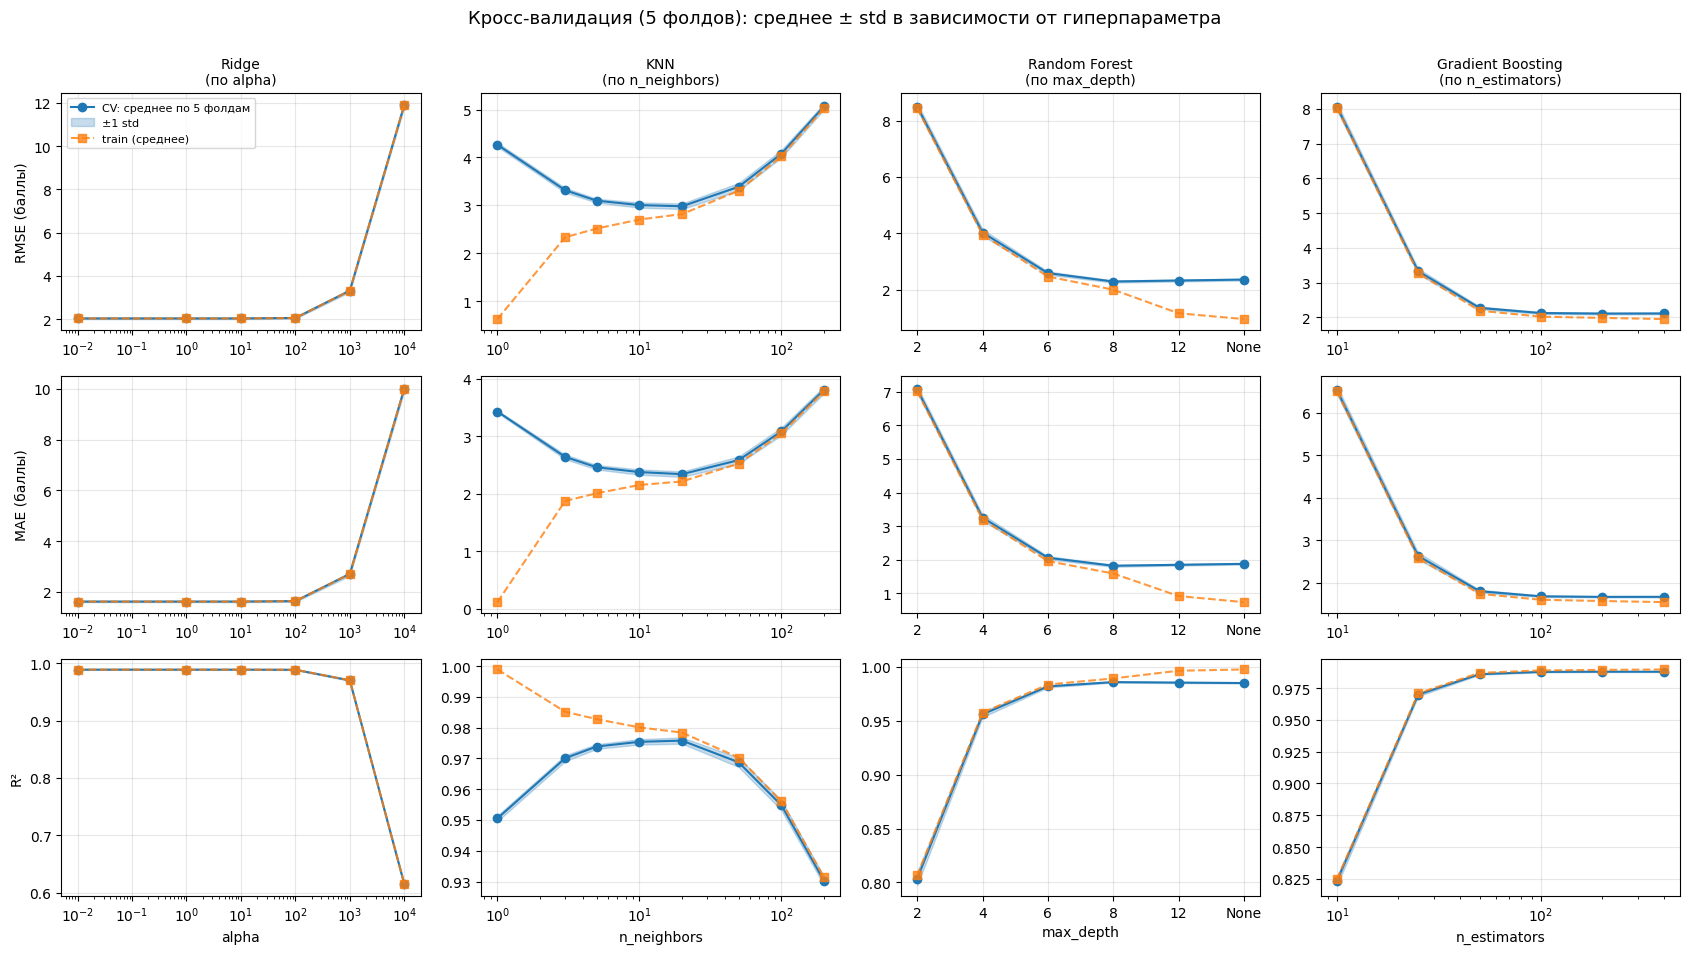

In [39]:
plot_sweeps(cv_df, "cv", "02_cv_metrics_vs_hyperparams.png",
            "Кросс-валидация (5 фолдов): среднее ± std в зависимости от гиперпараметра")

### Выводы по пунктам 5–6 (кросс-валидация)
**Те же оптимумы, что и на валидации:** KNN – k ≈ 20, Random Forest – глубина 8, Gradient Boosting – 100–200 деревьев, Ridge – `alpha ≤ 10`. Значит, выводы не артефакт одного разбиения.

**Устойчивость.** Std между фолдами для хороших конфигураций 0.025–0.06 RMSE (1–2% от значения), полоса ±std на графиках узкая. Больше всего «шумят» слабые модели (Random Forest с глубиной 2: 0.115). Метрики на val и среднее по CV отличаются у хороших моделей не более чем на ~0.05 – валидационное разбиение было репрезентативным.

**Зачем нужна кросс-валидация – наглядный пример.** На одном val-разбиении лучшей оказалась Ridge с `alpha=10` (RMSE 2.0178), а по CV значения `alpha` = 0.01, 1 и 10 неразличимы (2.0375, 2.0375, 2.0377: разница 0.0002 при стандартной ошибке 0.013). Различия в третьем знаке на одном разбиении – случайность, и только CV позволяет это увидеть.

**Ранжирование семейств по CV RMSE:** Ridge 2.04 < Gradient Boosting 2.11 < Random Forest 2.28 < KNN 2.98 (лучшие конфигурации). Разрыв Ridge–бустинг (0.07) больше стандартного отклонения (≈ 0.03), то есть устойчив, но практически мал: 0.07 балла из 100.

## 7. Итоговая таблица
Объединяем: метрики на одном валидационном разбиении и среднее ± std по кросс-валидации. Baseline включён для сравнения.

In [40]:
def hp_string(mname, v):
    g = GRID[mname]
    return f"{g['param']}={v}; {g['fixed']}"

summary = []
for _, r in baseline_df.iterrows():
    summary.append({"Модель": r["Модель"], "Гиперпараметры": "—", "val RMSE": r.val_rmse, "val MAE": r.val_mae, "val R²": r.val_r2,
                    "CV RMSE": f"{r.cv_rmse_mean:.3f} ± {r.cv_rmse_std:.3f}", "CV MAE": f"{r.cv_mae_mean:.3f} ± {r.cv_mae_std:.3f}",
                    "CV R²": f"{r.cv_r2_mean:.4f} ± {r.cv_r2_std:.4f}"})
for (_, a), (_, b) in zip(val_df.iterrows(), cv_df.iterrows()):
    summary.append({"Модель": a.model, "Гиперпараметры": hp_string(a.model, a.value),
                    "val RMSE": a.val_rmse, "val MAE": a.val_mae, "val R²": a.val_r2,
                    "CV RMSE": f"{b.cv_rmse_mean:.3f} ± {b.cv_rmse_std:.3f}", "CV MAE": f"{b.cv_mae_mean:.3f} ± {b.cv_mae_std:.3f}",
                    "CV R²": f"{b.cv_r2_mean:.4f} ± {b.cv_r2_std:.4f}"})
summary_df = pd.DataFrame(summary)
summary_df[["val RMSE", "val MAE"]] = summary_df[["val RMSE", "val MAE"]].round(3)
summary_df["val R²"] = summary_df["val R²"].round(4)

def to_markdown(t):
    def fmt(col, v):
        return (f"{v:.4f}" if "R²" in col else f"{v:.3f}") if isinstance(v, float) else str(v)
    head = "| " + " | ".join(t.columns) + " |\n|" + "|".join("---" for _ in t.columns) + "|\n"
    return head + "\n".join("| " + " | ".join(fmt(c, v) for c, v in zip(t.columns, row)) + " |" for row in t.itertuples(index=False))

summary_df.to_csv(RES / "summary_table.csv", index=False, encoding="utf-8-sig")
(RES / "summary_table.md").write_text(to_markdown(summary_df), encoding="utf-8")
val_df.to_csv(RES / "validation_results.csv", index=False)
cv_df.to_csv(RES / "cv_results.csv", index=False)
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(summary_df)

,Модель,Гиперпараметры,val RMSE,val MAE,val R²,CV RMSE,CV MAE,CV R²
0,Baseline: Mean,—,19.146,16.086,-0.0006,19.188 ± 0.101,16.188 ± 0.100,-0.0011 ± 0.0006
1,Baseline: Median,—,19.146,16.086,-0.0006,19.185 ± 0.101,16.185 ± 0.100,-0.0007 ± 0.0003
2,Baseline: LinReg по Previous Scores,—,7.718,6.617,0.8374,7.726 ± 0.044,6.589 ± 0.056,0.8377 ± 0.0019
3,Ridge,alpha=0.01; StandardScaler,2.019,1.597,0.9889,2.038 ± 0.030,1.619 ± 0.022,0.9887 ± 0.0003
4,Ridge,alpha=1; StandardScaler,2.019,1.597,0.9889,2.038 ± 0.030,1.619 ± 0.022,0.9887 ± 0.0003
5,Ridge,alpha=10; StandardScaler,2.018,1.597,0.9889,2.038 ± 0.030,1.619 ± 0.023,0.9887 ± 0.0003
6,Ridge,alpha=100; StandardScaler,2.030,1.611,0.9888,2.059 ± 0.032,1.637 ± 0.028,0.9885 ± 0.0004
7,Ridge,alpha=1000; StandardScaler,3.360,2.729,0.9692,3.320 ± 0.059,2.705 ± 0.069,0.9700 ± 0.0009
8,Ridge,alpha=10000; StandardScaler,12.120,10.150,0.5990,11.895 ± 0.083,10.006 ± 0.091,0.6153 ± 0.0020
9,KNN,"n_neighbors=1; weights=uniform, StandardScaler",4.229,3.403,0.9512,4.266 ± 0.042,3.433 ± 0.020,0.9505 ± 0.0009


## 8. Выбор лучшей модели и оценка на тесте
**Критерий выбора:** минимальный средний RMSE по кросс-валидации. Кросс-валидация надёжнее одного валидационного разбиения: она усредняет 5 оценок и показывает разброс.
Если несколько конфигураций различаются меньше, чем на величину шума (стандартная ошибка = std / √5), то они **статистически неразличимы**; это нужно честно отметить в выводах – выбор между ними на качество не влияет.

In [41]:
cv_sorted = cv_df.sort_values("cv_rmse_mean").reset_index(drop=True)
cv_sorted["SE (std/√5)"] = cv_sorted["cv_rmse_std"] / np.sqrt(5)
best = cv_sorted.iloc[0]
cv_sorted["в пределах 1 SE от лучшей"] = cv_sorted["cv_rmse_mean"] <= best["cv_rmse_mean"] + best["SE (std/√5)"]
display(cv_sorted[["model", "param", "value", "cv_rmse_mean", "cv_rmse_std", "SE (std/√5)", "cv_r2_mean", "в пределах 1 SE от лучшей"]].head(8).round(4))
print("\nКонфигурации, неотличимые от лучшей в пределах 1 SE:")
print(cv_sorted[cv_sorted["в пределах 1 SE от лучшей"]][["model", "param", "value"]].to_string(index=False))

,model,param,value,cv_rmse_mean,cv_rmse_std,SE (std/√5),cv_r2_mean,в пределах 1 SE от лучшей
0,Ridge,alpha,0.01,2.0375,0.0296,0.0132,0.9887,True
1,Ridge,alpha,1,2.0375,0.0296,0.0133,0.9887,True
2,Ridge,alpha,10,2.0377,0.0297,0.0133,0.9887,True
3,Ridge,alpha,100,2.0593,0.0319,0.0143,0.9885,False
4,Gradient Boosting,n_estimators,200,2.1094,0.0246,0.0110,0.9879,False
5,Gradient Boosting,n_estimators,400,2.1128,0.0245,0.0110,0.9879,False
6,Gradient Boosting,n_estimators,100,2.1247,0.0265,0.0119,0.9877,False
7,Gradient Boosting,n_estimators,50,2.2736,0.0390,0.0174,0.9859,False



Конфигурации, неотличимые от лучшей в пределах 1 SE:
model param value
Ridge alpha  0.01
Ridge alpha     1
Ridge alpha    10


In [42]:
BEST_MODEL = best["model"]
BEST_VALUE = next(v for v in GRID[BEST_MODEL]["values"] if str(v) == best["value"])   # возвращаем исходный тип (int / float / None)
print(f"ЛУЧШАЯ МОДЕЛЬ: {BEST_MODEL}, {GRID[BEST_MODEL]['param']} = {BEST_VALUE}")

final = GRID[BEST_MODEL]["build"](BEST_VALUE).fit(X_train_full, y_train_full)     # обучение на ВСЕХ обучающих данных
pred_test = final.predict(X_test)                                                 # единственное обращение к тесту
test_m = metrics(y_test, pred_test)

# для честного сравнения baseline тоже переобучаем на train_full
test_rows = [{"Модель": f"{BEST_MODEL} ({GRID[BEST_MODEL]['param']}={BEST_VALUE})", **{k.upper(): v for k, v in test_m.items()}}]
for name, mdl in baselines.items():
    mdl.fit(X_train_full, y_train_full)
    test_rows.append({"Модель": name, **{k.upper(): v for k, v in metrics(y_test, mdl.predict(X_test)).items()}})
test_df = pd.DataFrame(test_rows)
display(test_df.round(4))
test_df.to_csv(RES / "test_results.csv", index=False)

# доверительный интервал RMSE на тесте (bootstrap по остаткам)
rng = np.random.default_rng(SEED)
res_test = (y_test - pred_test).to_numpy()
boot = [np.sqrt(np.mean(rng.choice(res_test, len(res_test)) ** 2)) for _ in range(2000)]
print(f"\nRMSE на тесте = {test_m['rmse']:.3f}, 95% bootstrap-интервал [{np.percentile(boot, 2.5):.3f}; {np.percentile(boot, 97.5):.3f}]")
print(f"RMSE по кросс-валидации для этой модели = {best['cv_rmse_mean']:.3f} ± {best['cv_rmse_std']:.3f}")

ЛУЧШАЯ МОДЕЛЬ: Ridge, alpha = 0.01


,Модель,RMSE,MAE,R2
0,Ridge (alpha=0.01),2.0751,1.6470,0.9884
1,Baseline: Mean,19.3010,16.2526,-0.0010
2,Baseline: Median,19.3042,16.2537,-0.0013
3,Baseline: LinReg по Previous Scores,7.8173,6.7087,0.8358



RMSE на тесте = 2.075, 95% bootstrap-интервал [2.010; 2.142]
RMSE по кросс-валидации для этой модели = 2.038 ± 0.030


## 9. Анализ ошибок лучшей модели (график остатков)
Остаток = фактическое – предсказанное. У хорошей регрессии остатки: центрированы около нуля, не зависят от предсказания и признаков (нет структуры), приблизительно нормальны, без тяжёлых «хвостов».

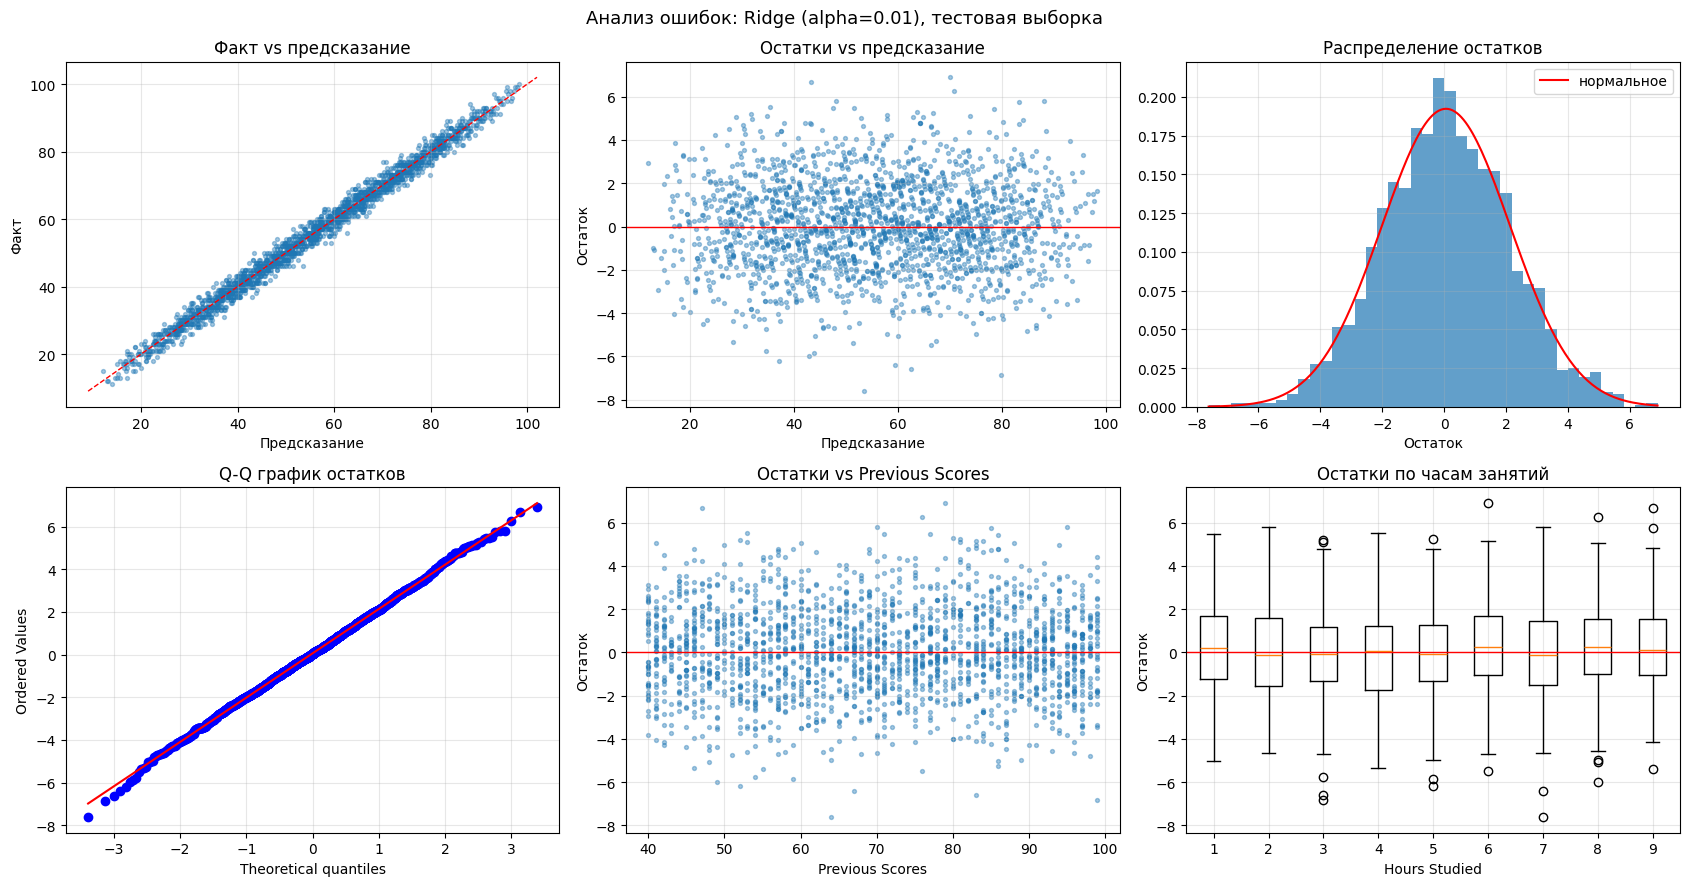

In [43]:
resid = y_test.to_numpy() - pred_test
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
ax[0, 0].scatter(pred_test, y_test, s=8, alpha=.4)
lim = [min(pred_test.min(), y_test.min()) - 2, max(pred_test.max(), y_test.max()) + 2]
ax[0, 0].plot(lim, lim, "r--", lw=1); ax[0, 0].set(xlabel="Предсказание", ylabel="Факт", title="Факт vs предсказание")
ax[0, 1].scatter(pred_test, resid, s=8, alpha=.4); ax[0, 1].axhline(0, color="r", lw=1)
ax[0, 1].set(xlabel="Предсказание", ylabel="Остаток", title="Остатки vs предсказание")
ax[0, 2].hist(resid, bins=40, density=True, alpha=.7)
xs = np.linspace(resid.min(), resid.max(), 200); ax[0, 2].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), "r-", label="нормальное")
ax[0, 2].set(xlabel="Остаток", title="Распределение остатков"); ax[0, 2].legend()
stats.probplot(resid, dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("Q-Q график остатков")
ax[1, 1].scatter(X_test["Previous Scores"], resid, s=8, alpha=.4); ax[1, 1].axhline(0, color="r", lw=1)
ax[1, 1].set(xlabel="Previous Scores", ylabel="Остаток", title="Остатки vs Previous Scores")
hours = sorted(X_test["Hours Studied"].unique())
groups = [resid[X_test["Hours Studied"].to_numpy() == h] for h in hours]
ax[1, 2].boxplot(groups, tick_labels=hours); ax[1, 2].axhline(0, color="r", lw=1)
ax[1, 2].set(xlabel="Hours Studied", ylabel="Остаток", title="Остатки по часам занятий")
fig.suptitle(f"Анализ ошибок: {BEST_MODEL} ({GRID[BEST_MODEL]['param']}={BEST_VALUE}), тестовая выборка", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "03_residuals_best_model.png", dpi=130, bbox_inches="tight"); plt.show()

In [44]:
summary_err = pd.Series({
    "Средний остаток (смещение)": resid.mean(),
    "Std остатков": resid.std(),
    "Доля |ошибка| ≤ 2 баллов": np.mean(np.abs(resid) <= 2),
    "Доля |ошибка| ≤ 5 баллов": np.mean(np.abs(resid) <= 5),
    "Максимальная |ошибка|": np.abs(resid).max(),
    "Асимметрия остатков": stats.skew(resid),
    "Эксцесс остатков": stats.kurtosis(resid),
    "Предсказаний > 100": int((pred_test > 100).sum()),
    "Корреляция остатков и предсказаний": np.corrcoef(resid, pred_test)[0, 1],
}).round(4)
display(summary_err.to_frame("значение"))
print("Округление цели до целого само даёт шум со std ≈ 0.289 (1/√12); остатки не могут быть меньше этого порога.")

worst = X_test.assign(Факт=y_test, Предсказание=pred_test.round(1), Остаток=resid.round(1))
worst = worst.reindex(worst["Остаток"].abs().sort_values(ascending=False).index).head(8)
display(worst)

,значение
Средний остаток (смещение),0.0609
Std остатков,2.0742
Доля |ошибка| ≤ 2 баллов,0.6714
Доля |ошибка| ≤ 5 баллов,0.9828
Максимальная |ошибка|,7.6098
Асимметрия остатков,0.0058
Эксцесс остатков,0.0648
Предсказаний > 100,0.0000
Корреляция остатков и предсказаний,0.0036


Округление цели до целого само даёт шум со std ≈ 0.289 (1/√12); остатки не могут быть меньше этого порога.


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Факт,Предсказание,Остаток
2465,7,64,0,4,3,46.0,53.6,-7.6
8179,6,79,1,9,9,77.0,70.1,6.9
3317,3,99,1,7,3,73.0,79.8,-6.8
2133,9,47,1,6,2,50.0,43.3,6.7
7476,3,83,1,5,3,56.0,62.6,-6.6
7914,7,67,1,9,2,53.0,59.4,-6.4
5566,8,76,0,8,4,77.0,70.8,6.2
5259,5,52,0,8,1,31.0,37.2,-6.2


,признак,рост RMSE при перемешивании,std
0,Previous Scores,23.073,0.247
1,Hours Studied,8.578,0.090
2,Sleep Hours,0.308,0.021
3,Sample Question Papers Practiced,0.154,0.011
4,Extracurricular Activities,0.057,0.006


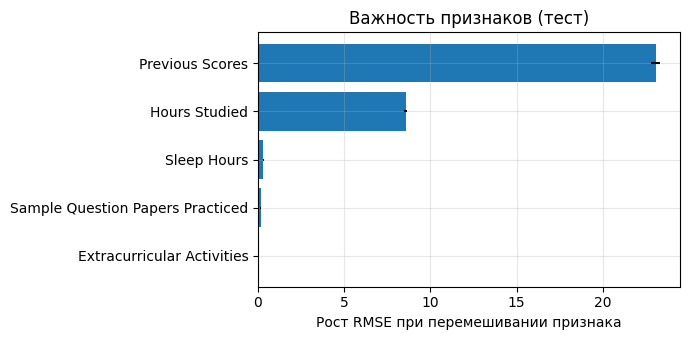

Свободный член: -33.981


,признак,коэффициент (баллов индекса на 1 ед. признака)
0,Hours Studied,2.851
1,Previous Scores,1.018
2,Extracurricular Activities,0.574
3,Sleep Hours,0.472
4,Sample Question Papers Practiced,0.189


In [45]:
# Что выучила модель: перестановочная важность признаков + (для линейной модели) коэффициенты в исходных единицах
pi = permutation_importance(final, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=20, random_state=SEED)
imp = pd.DataFrame({"признак": X.columns, "рост RMSE при перемешивании": pi.importances_mean, "std": pi.importances_std}).sort_values("рост RMSE при перемешивании", ascending=False)
display(imp.round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(imp["признак"][::-1], imp["рост RMSE при перемешивании"][::-1], xerr=imp["std"][::-1])
ax.set(xlabel="Рост RMSE при перемешивании признака", title="Важность признаков (тест)")
fig.tight_layout(); fig.savefig(FIG / "04_permutation_importance.png", dpi=130, bbox_inches="tight"); plt.show()
if BEST_MODEL == "Ridge":
    sc, rg = final.named_steps["scaler"], final.named_steps["m"]
    coef = pd.DataFrame({"признак": X.columns, "коэффициент (баллов индекса на 1 ед. признака)": rg.coef_ / sc.scale_})
    print(f"Свободный член: {rg.intercept_ - (rg.coef_ / sc.scale_ * sc.mean_).sum():.3f}")
    display(coef.round(3))

## Итоговые выводы
1. **Задача и метрики.** Регрессия по `Performance Index`; главная метрика RMSE (баллы индекса), дополнительно MAE и R².
2. **Лучшая модель – Ridge** (`alpha = 0.01`; значения 0.01–10 равнозначны, то есть по сути обычная линейная регрессия на стандартизованных признаках). CV RMSE 2.038 ± 0.030. **На тесте:** RMSE 2.075 (95% bootstrap-интервал 2.01–2.14), MAE 1.65, R² 0.988. Тестовая оценка лежит в пределах разброса CV, значит, выбор по кросс-валидации не привёл к «подгонке под валидацию».
3. **Сравнение с baseline на тесте.** Среднее: RMSE 19.3 → модель лучше ≈ в 9 раз. Линейная регрессия по одному `Previous Scores`: RMSE 7.8 → модель лучше ≈ в 3.8 раза, значит, остальные признаки вносят реальный вклад.
4. **Анализ ошибок.** Смещение 0.06 балла, std остатков 2.07; 67% предсказаний ошибаются не более чем на 2 балла, 98% – не более чем на 5, максимальная ошибка 7.6. Остатки практически нормальны (асимметрия 0.006, эксцесс 0.06), не зависят от предсказания (корреляция 0.004), от `Previous Scores` и `Hours Studied`. Систематических ошибок и предсказаний выше 100 нет.
5. **Почему простая линейная модель оказалось лучшей.** Зависимость цели от признаков по сути линейна плюс случайный шум со std ≈ 2. Деревья и KNN аппроксимируют плоскость ступеньками и усреднением соседей и платят за это дополнительной ошибкой; нелинейности, которую они могли бы уловить, в данных нет. Остаточная ошибка ≈ 2 балла – неустранимый шум (в данных есть 665 строк с совпадающими признаками, но разной целью). Дальнейшее усложнение модели на этих признаках не поможет; помочь могли бы только новые признаки или данные.
6. **Что выучила модель.** Почти всё определяют `Previous Scores` и `Hours Studied` (рост RMSE при перемешивании: 23.1 и 8.6 балла); `Sleep Hours` (0.31), `Sample Question Papers Practiced` (0.15) и `Extracurricular Activities` (0.06) влияют слабо, но не нулево. Коэффициенты: +2.85 балла за каждый час занятий, +1.02 за балл предыдущих результатов, +0.57 за внеучебную активность, +0.47 за час сна, +0.19 за решённый пробник. Это ассоциации, а не причинно-следственные связи.
7. **Ограничения.** (а) Данные выглядят синтетическими (почти идеальная линейность, нормальный шум, целочисленные признаки), поэтому на реальных студентах R² ≈ 0.99 ожидать нельзя. (б) Гиперпараметры подбирались по одному за раз, остальные фиксировались (`learning_rate`, `max_depth`, `n_estimators` леса); многомерный поиск (GridSearchCV) возможен, но при таком потолке шума выигрыша не даст. (в) Метрики стоит сверить с паспортом датасета и при необходимости дополнить обоснование ссылками на него.